## Previous anchor point code

In [ ]:
import pandas as pd
import numpy as np
from math import radians, cos, sin, asin, sqrt
from datetime import datetime, time

# --- Configuration & Thresholds ---
DIST_THRESHOLD_METERS = 100  # Distance to consider a person "moved"
STAY_DURATION_LIMIT_HRS = 6  # Updated to 6 hours as requested
HOME_WINDOW = (time(17, 0), time(9, 0))  # 5 PM to 9 AM
WORK_WINDOW = (time(9, 0), time(17, 0))  # 9 AM to 5 PM
EARLY_HOME_TRIGGER = time(16, 0)         # 4 PM check

def haversine(lat1, lon1, lat2, lon2):
    """Calculate the great circle distance between two points in meters."""
    R = 6371000
    lat1, lon1, lat2, lon2 = map(radians, [lat1, lon1, lat2, lon2])
    dlat = lat2 - lat1
    dlon = lon2 - lon1
    a = sin(dlat/2)**2 + cos(lat1) * cos(lat2) * sin(dlon/2)**2
    return 2 * R * asin(sqrt(a))

# 1. Load Data with the Date Parsing Fix
df = pd.read_csv('Location_multi_participants.csv')
# FIX: Using format='mixed' to handle milliseconds (.828)
df['datetime'] = pd.to_datetime(df['date'] + ' ' + df['time'], format='mixed')
df = df.sort_values(['participant_id', 'datetime'])

# --- PHASE 1: ANCHOR IDENTIFICATION ---
anchors = {}
for pid, group in df.groupby('participant_id'):
    # Home Anchor: Most frequent location between 12 AM and 6 AM
    night_pings = group[(group['datetime'].dt.time >= time(0, 0)) &
                        (group['datetime'].dt.time <= time(6, 0))]

    if not night_pings.empty:
        home_loc = night_pings.groupby([night_pings['latitude'].round(4),
                                        night_pings['longitude'].round(4)]).size().idxmax()
    else:
        home_loc = (group.iloc[0]['latitude'], group.iloc[0]['longitude'])

    # Work Anchor: Most frequent non-home location between 10 AM and 3 PM
    work_pings = group[(group['datetime'].dt.time >= time(10, 0)) &
                        (group['datetime'].dt.time <= time(15, 0))]

    # Filter out points too close to home
    work_pings = work_pings[work_pings.apply(lambda r: haversine(r['latitude'], r['longitude'],
                                                                 home_loc[0], home_loc[1]) > 300, axis=1)]

    if not work_pings.empty:
        work_loc = work_pings.groupby([work_pings['latitude'].round(4),
                                        work_pings['longitude'].round(4)]).size().idxmax()
    else:
        work_loc = None

    anchors[pid] = {'home': home_loc, 'work': work_loc}

# --- PHASE 2: SEQUENTIAL LABELING ---
results = []
for (pid, day), group in df.groupby(['participant_id', 'date']):
    group = group.sort_values('datetime')
    ref_point = group.iloc[0]
    p_home = anchors[pid]['home']
    p_work = anchors[pid]['work']

    for i, row in group.iterrows():
        dist_from_ref = haversine(row['latitude'], row['longitude'],
                                  ref_point['latitude'], ref_point['longitude'])

        # Trigger reference change if user moved
        if dist_from_ref > DIST_THRESHOLD_METERS:
            ref_point = row

        current_time = row['datetime'].time()
        dist_to_home = haversine(row['latitude'], row['longitude'], p_home[0], p_home[1])
        dist_to_work = haversine(row['latitude'], row['longitude'], p_work[0], p_work[1]) if p_work else 99999

        label = "Other"

        # Logic 1: Late Night/Evening Home Arrival
        if dist_to_home < DIST_THRESHOLD_METERS:
            label = "Home"
        # Logic 2: Early Home Transition (4 PM Rule)
        elif current_time >= EARLY_HOME_TRIGGER and dist_to_home < DIST_THRESHOLD_METERS:
            label = "Home"
        # Logic 3: Work Window
        elif time(9, 0) <= current_time <= time(17, 0):
            label = "Work" if dist_to_work < DIST_THRESHOLD_METERS else "Other"
        # Logic 4: Evening Window (prioritize Home Anchor)
        else:
            label = "Home" if dist_to_home < DIST_THRESHOLD_METERS else "Other"

        results.append({
            'measurement_id': row['measurement_id'],
            'participant_id': pid,
            'datetime': row['datetime'],
            'label': label
        })

labeled_df = pd.DataFrame(results)

# --- PHASE 3: THE 6-HOUR "OTHER" REFINEMENT ---
labeled_df['stay_id'] = (labeled_df['label'] != labeled_df['label'].shift()).cumsum()

for sid, stay_group in labeled_df.groupby('stay_id'):
    if stay_group.iloc[0]['label'] == "Other":
        # Check if this 'Other' stay happened during the night window
        stay_time = stay_group.iloc[0]['datetime'].time()
        if stay_time > time(17, 0) or stay_time < time(9, 0):
            duration_hrs = (stay_group.iloc[-1]['datetime'] - stay_group.iloc[0]['datetime']).total_seconds() / 3600

            # If they stay at a non-home location for more than 6 hours at night,
            # we keep it as 'Other' (or you could change it to 'Secondary_Home' here)
            if duration_hrs > STAY_DURATION_LIMIT_HRS:
                pass

# Final merge and save
final_df = df.merge(labeled_df[['measurement_id', 'label']], on='measurement_id')
final_df.to_csv('Location_Labeled_Cleaned.csv', index=False)
print("Done! File saved as Location_Labeled_Cleaned.csv")

FileNotFoundError: [Errno 2] No such file or directory: 'Location_multi_participants.csv'

## Update for 31st meeting

all files are saved here for documentation. These have been run locally

### Logic
connectionId == participant_id
AND
date matches
AND
location_time ∈ [timeStampStart, timeStampStop]

In [ ]:
import pandas as pd

# Load the datasets
ema_df = pd.read_excel('Full_EMA_data_daily_affect.xlsx')
loc_df = pd.read_excel('Location_multi_participants.xlsx')

# 1. Standardize IDs
loc_df = loc_df.rename(columns={'participant_id': 'connectionId'})

# 2. Extract and format Dates (Handling UTC)
# Using errors='coerce' just in case there are empty rows in your Excel
ema_df['extracted_date'] = pd.to_datetime(ema_df['timeStampScheduled'], utc=True, errors='coerce').dt.date
loc_df['date'] = pd.to_datetime(loc_df['date'], errors='coerce').dt.date

# 3. Convert Time columns (The Fix for ".828" and Timezones)
# Setting utc=True ensures both dataframes speak the same 'timezone language'
ema_df['timeStampStart'] = pd.to_datetime(ema_df['timeStampStart'], utc=True, errors='coerce')
ema_df['timeStampStop'] = pd.to_datetime(ema_df['timeStampStop'], utc=True, errors='coerce')

# Combined date and time string conversion with 'mixed' format to handle milliseconds
loc_df['full_loc_time'] = pd.to_datetime(
    loc_df['date'].astype(str) + ' ' + loc_df['time'].astype(str),
    format='mixed',
    utc=True,
    errors='coerce'
)

# 4. Perform the Merge
merged_df = pd.merge(
    loc_df,
    ema_df,
    left_on=['connectionId', 'date'],
    right_on=['connectionId', 'extracted_date']
)

# 5. Filter
mask = (merged_df['full_loc_time'] >= merged_df['timeStampStart']) & \
       (merged_df['full_loc_time'] <= merged_df['timeStampStop'])

final_output = merged_df[mask]

# 6. Save
if len(final_output) > 50000:
    final_output = final_output.head(50000)

final_output.to_csv('merged_ema_location_data.csv', index=False)
print(f"Process complete. {len(final_output)} rows saved.")

Process complete. 3678 rows saved.


but this has a constraint of >50000, bcox file was getting too large

### formatting- FOR BETTER UNDERSTANDING

In [ ]:
import pandas as pd

# 1. Load the merged data
df = pd.read_csv('merged_ema_location_data.csv')

# 2. Ensure types are correct for sorting
df['date'] = pd.to_datetime(df['date']).dt.date
# Sorting by ID first, then Date, then the specific time
df = df.sort_values(by=['connectionId', 'date', 'full_loc_time'])

# 3. Create a list to hold our data frames (more efficient than appending to one df)
grouped_list = []
empty_rows = pd.DataFrame([[None] * len(df.columns)], columns=df.columns)

# 4. Group by connectionId and Date
# This mimics the structure in your screenshot
for (conn_id, date), group in df.groupby(['connectionId', 'date']):
    # Add the data for this specific ID on this specific Date
    grouped_list.append(group)

    # Add 5 empty lines as a visual gap
    for _ in range(5):
        grouped_list.append(empty_rows)

# 5. Concatenate everything back together
final_formatted_df = pd.concat(grouped_list, ignore_index=True)

# 6. Save to a new CSV
output_path = 'formatted_ema_location_groups.csv'
final_formatted_df.to_csv(output_path, index=False, na_rep='')

print(f"Success! Formatted file saved as {output_path}")

### behavioural analysis

On Location_labeled_cleaned

1. calculated durations
2. converted to percentages
3. calculated daily roaming entropy

output in form of per person per day

In [ ]:
import pandas as pd
import numpy as np

# Load dataset
df = pd.read_csv("Location_Labeled_Cleaned.csv")

# Convert datetime
df['datetime'] = pd.to_datetime(df['datetime'], format='mixed')

# Sort by participant and time
df = df.sort_values(['participant_id', 'datetime'])

# Extract date
df['date'] = df['datetime'].dt.date

# Forward time difference
df['next_time'] = df.groupby('participant_id')['datetime'].shift(-1)
df['time_diff'] = (df['next_time'] - df['datetime']).dt.total_seconds()

# Maximum allowed gap (30 min)
MAX_GAP = 30 * 60
df.loc[df['time_diff'] > MAX_GAP, 'time_diff'] = np.nan

locations = ['Home', 'Work', 'Other']

rows = []

# Process per participant per day
for (pid, day), day_df in df.groupby(['participant_id', 'date']):

    valid = day_df.dropna(subset=['time_diff'])

    time_spent = valid.groupby('label')['time_diff'].sum()
    time_spent = time_spent.reindex(locations, fill_value=0)

    total_time = time_spent.sum()

    if total_time == 0:
        continue

    percentages = (time_spent / total_time) * 100

    p = time_spent / total_time
    p = p[p > 0]

    n = len(locations)

    RE = -np.sum(p * np.log2(p)) / np.log2(n)

    rows.append({
        "participant_id": pid,
        "date": day,
        "home_percent": round(percentages['Home'], 2),
        "work_percent": round(percentages['Work'], 2),
        "other_percent": round(percentages['Other'], 2),
        "daily_roaming_entropy": round(RE, 4)
    })

results_df = pd.DataFrame(rows)

# Sort output
results_df = results_df.sort_values(['participant_id', 'date'])

# ---- Write CSV with headers ----
with open("daily_mobility_metrics.csv", "w") as f:

    # Write header
    f.write("participant_id,date,home_percent,work_percent,other_percent,daily_roaming_entropy\n")

    prev_pid = None

    for _, row in results_df.iterrows():

        if prev_pid is not None and prev_pid != row['participant_id']:
            f.write("\n\n")  # blank lines between participants

        line = f"{row['participant_id']},{row['date']},{row['home_percent']},{row['work_percent']},{row['other_percent']},{row['daily_roaming_entropy']}\n"
        f.write(line)

        prev_pid = row['participant_id']

print("daily_mobility_metrics.csv created successfully")

Build a depression-related affect risk target using:

1. formatted_ema_location_groups.csv  (script 2 output: row-per-GPS-ping,
                                        EMA cols attached via
                                        connectionId + date + time-window
                                        match, with 5 blank rows separating
                                        each participant-day group)
2. daily_mobility_metrics.csv         (script 3 output: one row per
                                        participant-day, home/work/other
                                        percent + roaming entropy, derived
                                        from the Home/Work/Other-labelled
                                        location file -- a separate pipeline
                                        from raw lat/long, so it's still
                                        pulled in separately here)

Output

depression_risk_features.csv
   - one row per participant-day with EMA affect aggregates, person-level
     baselines/deviations (affect + mobility), continuous risk score, and
     binary risk label.

In [ ]:
import pandas as pd
import numpy as np

# ---------------------------------------------------------------------------
# 1. Load
# ---------------------------------------------------------------------------
merged_df = pd.read_csv('formatted_ema_location_groups.csv')
mobility_df = pd.read_csv('daily_mobility_metrics.csv')

# Drop the blank separator rows inserted by script 2 (rows where connectionId
# is empty are the visual spacer rows, not real data)
merged_df = merged_df.dropna(subset=['connectionId'])

merged_df['date'] = pd.to_datetime(merged_df['date'], errors='coerce').dt.date
mobility_df = mobility_df.rename(columns={'participant_id': 'connectionId'})
mobility_df['date'] = pd.to_datetime(mobility_df['date'], errors='coerce').dt.date

# ---------------------------------------------------------------------------
# 2. De-duplicate back to one row per EMA beep before aggregating.
#    This file still has one row per GPS ping matched to an EMA window, so
#    the same beep repeats for every ping inside it. Collapse on a beep
#    identifier first so denser GPS logging doesn't skew the daily average.
# ---------------------------------------------------------------------------
beep_id_cols = ['connectionId', 'BeepNo', 'ObsNo', 'timeStampStart']
ema_beeps = merged_df.drop_duplicates(subset=beep_id_cols)[
    beep_id_cols + ['date', 'Momentary_positive_emotions', 'Momentary_negative_emotions']
]

# ---------------------------------------------------------------------------
# 3. Collapse beep-level EMA -> participant-day level
# ---------------------------------------------------------------------------
daily_ema = (
    ema_beeps
    .groupby(['connectionId', 'date'], as_index=False)[
        ['Momentary_positive_emotions', 'Momentary_negative_emotions']
    ]
    .mean()
    .rename(columns={
        'Momentary_positive_emotions': 'pos_emotion',
        'Momentary_negative_emotions': 'neg_emotion',
    })
)

daily_ema = daily_ema.dropna(subset=['pos_emotion', 'neg_emotion'])

# ---------------------------------------------------------------------------
# 4. Person-level baselines + deviations for affect
# ---------------------------------------------------------------------------
baseline = (
    daily_ema
    .groupby('connectionId')[['pos_emotion', 'neg_emotion']]
    .agg(['mean', 'std'])
)
baseline.columns = ['_'.join(c) for c in baseline.columns]
baseline = baseline.reset_index()

daily_ema = daily_ema.merge(baseline, on='connectionId', how='left')

daily_ema['pos_emotion_baseline'] = daily_ema['pos_emotion_mean']
daily_ema['neg_emotion_baseline'] = daily_ema['neg_emotion_mean']

daily_ema['pos_emotion_deviation'] = daily_ema['pos_emotion'] - daily_ema['pos_emotion_baseline']
daily_ema['neg_emotion_deviation'] = daily_ema['neg_emotion'] - daily_ema['neg_emotion_baseline']

daily_ema['pos_emotion_z'] = np.where(
    daily_ema['pos_emotion_std'] > 0,
    daily_ema['pos_emotion_deviation'] / daily_ema['pos_emotion_std'],
    0.0,
)
daily_ema['neg_emotion_z'] = np.where(
    daily_ema['neg_emotion_std'] > 0,
    daily_ema['neg_emotion_deviation'] / daily_ema['neg_emotion_std'],
    0.0,
)

daily_ema = daily_ema.drop(columns=['pos_emotion_mean', 'neg_emotion_mean'])

# ---------------------------------------------------------------------------
# 5. Depression-related affect risk target
# ---------------------------------------------------------------------------
daily_ema['risk_score'] = daily_ema['neg_emotion_z'] - daily_ema['pos_emotion_z']

# Literal definition: negative above usual AND positive below usual.
# NOTE: triggers on any deviation, however small -> flags ~half of all days.
daily_ema['risk_label'] = (
    (daily_ema['neg_emotion_deviation'] > 0) &
    (daily_ema['pos_emotion_deviation'] < 0)
).astype(int)

# Stricter, recommended for modelling: both deviations >= 0.5 SD
THRESHOLD_SD = 0.5
daily_ema['risk_label_strict'] = (
    (daily_ema['neg_emotion_z'] > THRESHOLD_SD) &
    (daily_ema['pos_emotion_z'] < -THRESHOLD_SD)
).astype(int)

# ---------------------------------------------------------------------------
# 6. Person-level baselines + deviations for mobility
# ---------------------------------------------------------------------------
mob_cols = ['home_percent', 'work_percent', 'other_percent', 'daily_roaming_entropy']

mob_baseline = mobility_df.groupby('connectionId')[mob_cols].mean()
mob_baseline.columns = [f'{c}_baseline' for c in mob_baseline.columns]
mob_baseline = mob_baseline.reset_index()

mobility_df = mobility_df.merge(mob_baseline, on='connectionId', how='left')

for c in mob_cols:
    mobility_df[f'{c}_deviation'] = mobility_df[c] - mobility_df[f'{c}_baseline']

mobility_df['entropy_deviation'] = mobility_df['daily_roaming_entropy_deviation']

# ---------------------------------------------------------------------------
# 7. Merge affect-risk features with mobility features
# ---------------------------------------------------------------------------
final_df = pd.merge(
    daily_ema,
    mobility_df,
    on=['connectionId', 'date'],
    how='inner',   # only keep participant-days present in both
)

final_df = final_df.sort_values(['connectionId', 'date'])

# ---------------------------------------------------------------------------
# 8. Save
# ---------------------------------------------------------------------------
final_df.to_csv('depression_risk_features.csv', index=False)

print(f"Done. {len(final_df)} participant-days written to depression_risk_features.csv")
print(f"Elevated risk (literal def.): {final_df['risk_label'].sum()} days "
      f"({final_df['risk_label'].mean()*100:.1f}%)")
print(f"Elevated risk (strict, 0.5SD): {final_df['risk_label_strict'].sum()} days "
      f"({final_df['risk_label_strict'].mean()*100:.1f}%)")

Done. 474 participant-days written to depression_risk_features.csv
Elevated risk (literal def.): 139 days (29.3%)
Elevated risk (strict, 0.5SD): 86 days (18.1%)


One row per participant-day.

| Column | Description |
|--------|-------------|
| `connectionId` | Participant identifier |
| `date` | Calendar date for this participant-day |
| `pos_emotion` | Mean momentary positive emotion across all EMA beeps that day |
| `neg_emotion` | Mean momentary negative emotion across all EMA beeps that day |
| `pos_emotion_std` | Participant's own std. dev. of `pos_emotion` across their entire history (used to compute z-scores) |
| `neg_emotion_std` | Participant's own std. dev. of `neg_emotion` across their entire history |
| `pos_emotion_baseline` | Participant's own mean `pos_emotion` across their entire history |
| `neg_emotion_baseline` | Participant's own mean `neg_emotion` across their entire history |
| `pos_emotion_deviation` | `pos_emotion` − `pos_emotion_baseline` (today vs. this participant's usual) |
| `neg_emotion_deviation` | `neg_emotion` − `neg_emotion_baseline` |
| `pos_emotion_z` | `pos_emotion_deviation` standardized by `pos_emotion_std` (0 if std is 0) |
| `neg_emotion_z` | `neg_emotion_deviation` standardized by `neg_emotion_std` (0 if std is 0) |
| `risk_score` | Continuous risk measure: `neg_emotion_z − pos_emotion_z` |
| `risk_label` | Binary, "literal" definition: 1 if neg. deviation > 0 and pos. deviation < 0 (any magnitude — flags roughly half of days) |
| `risk_label_strict` | Binary, recommended target: 1 if `neg_emotion_z > 0.5 SD` and `pos_emotion_z < −0.5 SD` |
| `home_percent` | % of day's location pings classified as "home" |
| `work_percent` | % of day's location pings classified as "work" |
| `other_percent` | % of day's location pings classified as "other" |
| `daily_roaming_entropy` | Entropy of location distribution that day (higher = more spread across places) |
| `home_percent_baseline` | Participant's own mean `home_percent` across their history |
| `work_percent_baseline` | Participant's own mean `work_percent` across their history |
| `other_percent_baseline` | Participant's own mean `other_percent` across their history |
| `daily_roaming_entropy_baseline` | Participant's own mean `daily_roaming_entropy` |
| `home_percent_deviation` | `home_percent` − its baseline |
| `work_percent_deviation` | `work_percent` − its baseline |
| `other_percent_deviation` | `other_percent` − its baseline |
| `daily_roaming_entropy_deviation` | `daily_roaming_entropy` − its baseline |
| `entropy_deviation` | Duplicate of `daily_roaming_entropy_deviation` (kept for naming consistency with feature lists downstream) |

**Note:** `BeepNo`, `ObsNo`, `timeStampStart` from the input file are used only to de-duplicate GPS-ping repeats and don't survive into this output.

per id- the days we have data for

In [ ]:
import pandas as pd

df = pd.read_csv('depression_risk_features.csv')
df['date'] = pd.to_datetime(df['date'])
df = df.sort_values(['connectionId', 'date'])

for cid, group in df.groupby('connectionId'):
    dates = group['date'].dt.strftime('%Y-%m-%d').tolist()
    print(f"{cid}: {dates}")

133417.0: ['2023-02-25', '2023-02-26', '2023-02-28', '2023-03-01', '2023-03-03', '2023-03-05', '2023-03-06']
134650.0: ['2023-03-07', '2023-03-11', '2023-03-13']
134944.0: ['2023-03-02', '2023-03-03', '2023-03-04', '2023-03-07', '2023-03-08', '2023-03-10', '2023-03-11', '2023-03-14', '2023-03-15']
134947.0: ['2023-03-02', '2023-03-03', '2023-03-04', '2023-03-05', '2023-03-06', '2023-03-07', '2023-03-08', '2023-03-09', '2023-03-10', '2023-03-11', '2023-03-12', '2023-03-13', '2023-03-15']
134986.0: ['2023-03-02', '2023-03-03', '2023-03-04', '2023-03-08', '2023-03-11']
135043.0: ['2023-03-08']
135196.0: ['2023-03-06', '2023-03-11']
135205.0: ['2023-03-03', '2023-03-06', '2023-03-10', '2023-03-12', '2023-03-16']
135307.0: ['2023-03-04', '2023-03-05', '2023-03-16']
136522.0: ['2023-03-04', '2023-03-06', '2023-03-11', '2023-03-16']
136675.0: ['2023-03-04', '2023-03-05', '2023-03-06', '2023-03-07', '2023-03-08', '2023-03-09', '2023-03-10', '2023-03-11', '2023-03-12', '2023-03-13', '2023-03-15

since days are very irregular we did generation of lag features day wise, not row wise using groupby

Section 2 now loops per participant using actual date values — lag_1 is NaN unless a row for exactly yesterday exists; rolling means only include rows whose date falls within the true 3/7-day calendar window.

days_since_last_obs added per row, and included in every feature set so the model can see how stale its own lag/rolling inputs are.

we have two output csvs now- one dense participant data who have data for >=5days and the other csv for which consists the entire data


In [ ]:
import pandas as pd
import numpy as np
from sklearn.model_selection import GroupKFold
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score, accuracy_score, classification_report
from xgboost import XGBClassifier
import warnings
warnings.filterwarnings('ignore')

# ---------------------------------------------------------------------------
# 1. Load Data & Ensure Sorting
# ---------------------------------------------------------------------------
df = pd.read_csv('depression_risk_features.csv')
df['date'] = pd.to_datetime(df['date'])
df = df.sort_values(['connectionId', 'date']).reset_index(drop=True)

# ---------------------------------------------------------------------------
# 2. Calendar-Based Lag, Rolling, and Gap-Awareness Features
# ---------------------------------------------------------------------------
# Row-based shift()/rolling() would silently reach further back than 1/3/7
# calendar days whenever a participant has a gap. Instead, for every row we
# look at the *actual dates* available for that participant and only pull
# in observations that genuinely fall inside the calendar window.

print("Generating calendar-aware lag, rolling, and gap features...")

lag_cols   = ['home_percent', 'neg_emotion', 'pos_emotion', 'daily_roaming_entropy']
roll_cols  = ['home_percent', 'neg_emotion', 'daily_roaming_entropy']

def build_participant_features(g):
    g = g.sort_values('date').reset_index(drop=True)
    dates = g['date'].values

    # --- days_since_last_obs: exposes the gap instead of hiding it ---
    days_since = np.full(len(g), np.nan)
    days_since[1:] = (g['date'].iloc[1:].values - g['date'].iloc[:-1].values) / np.timedelta64(1, 'D')
    g['days_since_last_obs'] = days_since

    # --- 1-day lag: only counts if a row for EXACTLY yesterday exists ---
    for col in lag_cols:
        out = np.full(len(g), np.nan)
        for i in range(1, len(g)):
            gap = (g['date'].iloc[i] - g['date'].iloc[i - 1]).days
            if gap == 1:
                out[i] = g[col].iloc[i - 1]
        g[f'{col}_lag_1'] = out

    # --- 3-day / 7-day rolling: average only observations whose date
    #     actually falls within the last N calendar days (today included,
    #     consistent with your original closed='right' choice) ---
    for window in (3, 7):
        for col in roll_cols:
            out = np.full(len(g), np.nan)
            for i in range(len(g)):
                today = g['date'].iloc[i]
                mask = (g['date'] <= today) & (g['date'] > today - pd.Timedelta(days=window))
                out[i] = g.loc[mask, col].mean()
            g[f'mean_{col}_last_{window}_days'] = out

    return g

df = df.groupby('connectionId', group_keys=False).apply(build_participant_features)
df = df.rename(columns={
    'mean_neg_emotion_last_3_days': 'mean_neg_emotion_last_3_days',
    'mean_daily_roaming_entropy_last_3_days': 'mean_roaming_entropy_last_3_days',
    'mean_daily_roaming_entropy_last_7_days': 'mean_roaming_entropy_last_7_days',
})

# roaming_entropy_lag_1 name alignment (source col is daily_roaming_entropy)
df = df.rename(columns={'daily_roaming_entropy_lag_1': 'roaming_entropy_lag_1'})

# ---------------------------------------------------------------------------
# 3. Filter to Participants With Enough Density
# ---------------------------------------------------------------------------
# Lag/rolling features are structurally meaningless for participants with
# only 1-2 total observations. Set a minimum bar before these rows are
# allowed into the modeling dataset.
MIN_TOTAL_DAYS = 5

day_counts = df.groupby('connectionId')['date'].transform('count')
df_dense = df[day_counts >= MIN_TOTAL_DAYS].copy()

n_before, n_after = df['connectionId'].nunique(), df_dense['connectionId'].nunique()
print(f"Participants: {n_before} total -> {n_after} retained with >= {MIN_TOTAL_DAYS} days "
      f"({df_dense.shape[0]} rows of {df.shape[0]} total)")

# ---------------------------------------------------------------------------
# 4. Define Next-Day Target (Predicting Tomorrow's Risk)
# ---------------------------------------------------------------------------
grouped_dense = df_dense.groupby('connectionId')
df_dense['next_day_risk'] = grouped_dense['risk_label_strict'].shift(-1)

# Also require the target's next-day row to be an actual consecutive day,
# not a jump of several days pretending to be "tomorrow"
next_date = grouped_dense['date'].shift(-1)
gap_to_next = (next_date - df_dense['date']).dt.days
df_dense.loc[gap_to_next != 1, 'next_day_risk'] = np.nan

df_clean = df_dense.dropna(
    subset=['next_day_risk', 'home_percent_lag_1']
).reset_index(drop=True)

print(f"Final modeling rows after target/lag requirements: {len(df_clean)}")

# ---------------------------------------------------------------------------
# 5. Define Feature Sets for the 3 Model Types
# ---------------------------------------------------------------------------
ema_features = [
    'pos_emotion', 'neg_emotion', 'pos_emotion_deviation', 'neg_emotion_deviation',
    'neg_emotion_lag_1', 'pos_emotion_lag_1',
    'mean_neg_emotion_last_3_days', 'mean_neg_emotion_last_7_days',
    'days_since_last_obs'
]

gps_features = [
    'home_percent', 'work_percent', 'other_percent', 'daily_roaming_entropy',
    'home_percent_deviation', 'entropy_deviation',
    'home_percent_lag_1', 'roaming_entropy_lag_1',
    'mean_home_percent_last_3_days', 'mean_roaming_entropy_last_3_days',
    'mean_home_percent_last_7_days', 'mean_roaming_entropy_last_7_days',
    'days_since_last_obs'
]

combined_features = list(set(ema_features + gps_features))

feature_sets = {
    "EMA-Only": ema_features,
    "GPS-Only": gps_features,
    "Combined EMA + GPS": combined_features
}

# ---------------------------------------------------------------------------
# 6. Group-Aware Cross-Validation Evaluation Pipeline
# ---------------------------------------------------------------------------
X = df_clean
y = df_clean['next_day_risk'].astype(int)
groups = df_clean['connectionId']

gkf = GroupKFold(n_splits=5)
results = []

print("\n--- Starting Model Training and Evaluation ---")

for model_name, classifier in [("Logistic Regression", LogisticRegression(max_iter=1000, random_state=42)),
                               ("XGBoost", XGBClassifier(n_estimators=100, max_depth=3, learning_rate=0.05, random_state=42, eval_metric='logloss'))]:

    for set_name, features in feature_sets.items():
        auc_scores = []
        acc_scores = []

        for train_idx, test_idx in gkf.split(X, y, groups):
            X_train, X_test = X.loc[train_idx, features].copy(), X.loc[test_idx, features].copy()
            y_train, y_test = y.loc[train_idx], y.loc[test_idx]

            X_train.fillna(X_train.mean(), inplace=True)
            X_test.fillna(X_train.mean(), inplace=True)

            classifier.fit(X_train, y_train)

            preds_prob = classifier.predict_proba(X_test)[:, 1]
            preds_label = classifier.predict(X_test)

            if len(np.unique(y_test)) > 1:
                auc_scores.append(roc_auc_score(y_test, preds_prob))
            acc_scores.append(accuracy_score(y_test, preds_label))

        results.append({
            "Model": model_name,
            "Configuration": set_name,
            "Mean Accuracy": np.mean(acc_scores),
            "Mean ROC-AUC": np.mean(auc_scores) if auc_scores else np.nan
        })

# ---------------------------------------------------------------------------
# 7. Display Performance Summary Matrix
# ---------------------------------------------------------------------------
results_df = pd.DataFrame(results)
print("\n### Performance Benchmark Matrix Summary ###")
print(results_df.to_string(index=False))

df.to_csv('depression_risk_lagged_features.csv', index=False)
print("\nFull (unfiltered) lagged dataset saved as 'depression_risk_lagged_features.csv'.")
df_clean.to_csv('depression_risk_lagged_features_dense.csv', index=False)
print("Dense, modeling-ready subset saved as 'depression_risk_lagged_features_dense.csv'.")

Generating calendar-aware lag, rolling, and gap features...
Participants: 102 total -> 49 retained with >= 5 days (333 rows of 474 total)
Final modeling rows after target/lag requirements: 89

--- Starting Model Training and Evaluation ---

### Performance Benchmark Matrix Summary ###
              Model      Configuration  Mean Accuracy  Mean ROC-AUC
Logistic Regression           EMA-Only       0.765359      0.651316
Logistic Regression           GPS-Only       0.809150      0.386714
Logistic Regression Combined EMA + GPS       0.698693      0.572399
            XGBoost           EMA-Only       0.798693      0.549748
            XGBoost           GPS-Only       0.775817      0.473123
            XGBoost Combined EMA + GPS       0.798039      0.513518

Full (unfiltered) lagged dataset saved as 'depression_risk_lagged_features.csv'.
Dense, modeling-ready subset saved as 'depression_risk_lagged_features_dense.csv'.


output

Every column from script 1's output is carried through unchanged, plus:

| Column | Description |
|--------|-------------|
| `days_since_last_obs` | Calendar days between this row and the participant's previous row (NaN on each participant's first row) |
| `home_percent_lag_1` | Yesterday's `home_percent` — only filled if a row for exactly yesterday exists, else NaN |
| `neg_emotion_lag_1` | Yesterday's `neg_emotion`, same exactly-yesterday rule |
| `pos_emotion_lag_1` | Yesterday's `pos_emotion`, same rule |
| `roaming_entropy_lag_1` | Yesterday's `daily_roaming_entropy`, same rule |
| `mean_home_percent_last_3_days` | Mean `home_percent` over rows whose date falls in the trailing 3 calendar days (today included) |
| `mean_neg_emotion_last_3_days` | Same, for `neg_emotion` |
| `mean_roaming_entropy_last_3_days` | Same, for `daily_roaming_entropy` |
| `mean_home_percent_last_7_days` | Mean `home_percent` over the trailing 7 calendar days |
| `mean_neg_emotion_last_7_days` | Same, for `neg_emotion` |
| `mean_roaming_entropy_last_7_days` | Same, for `daily_roaming_entropy` |
| `next_day_risk` | Dense file only. Tomorrow's `risk_label_strict`, kept only if tomorrow is an actual consecutive day (else dropped, not just NaN) — this is the modeling target |

In [ ]:
"""
diagnostics.py
---------------
Companion script to the main modeling pipeline. Does NOT redo feature
engineering — it reads the CSVs already produced by the main script and
answers the two questions that the summary matrix alone can't answer:

  1. How imbalanced is next_day_risk, overall and inside each CV fold?
  2. What do accuracy/AUC look like fold-by-fold (not just averaged),
     so a single unlucky/lucky fold doesn't hide in the mean?

It also re-runs the density filter with the *other* option you had on the
table (>=3 observations within any rolling 7-day window) as an alternative
to the >=5-total-days rule, and reports how much data each rule keeps, so
you can compare before picking one.

Inputs expected (produced by the main script):
  - depression_risk_lagged_features.csv        (full, unfiltered, with
                                                 days_since_last_obs etc.)
  - depression_risk_lagged_features_dense.csv  (df_clean: the >=5-day,
                                                 consecutive-target subset
                                                 actually used for modeling)
"""

import pandas as pd
import numpy as np
from sklearn.model_selection import GroupKFold
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score, accuracy_score
from xgboost import XGBClassifier
import warnings
warnings.filterwarnings('ignore')

FULL_PATH = 'depression_risk_lagged_features.csv'
DENSE_PATH = 'depression_risk_lagged_features_dense.csv'

ema_features = [
    'pos_emotion', 'neg_emotion', 'pos_emotion_deviation', 'neg_emotion_deviation',
    'neg_emotion_lag_1', 'pos_emotion_lag_1',
    'mean_neg_emotion_last_3_days', 'mean_neg_emotion_last_7_days',
    'days_since_last_obs'
]

gps_features = [
    'home_percent', 'work_percent', 'other_percent', 'daily_roaming_entropy',
    'home_percent_deviation', 'entropy_deviation',
    'home_percent_lag_1', 'roaming_entropy_lag_1',
    'mean_home_percent_last_3_days', 'mean_roaming_entropy_last_3_days',
    'mean_home_percent_last_7_days', 'mean_roaming_entropy_last_7_days',
    'days_since_last_obs'
]

combined_features = list(set(ema_features + gps_features))

feature_sets = {
    "EMA-Only": ema_features,
    "GPS-Only": gps_features,
    "Combined EMA + GPS": combined_features
}

# ---------------------------------------------------------------------------
# 0. Sanity check: does days_since_last_obs actually exist in the full file?
# ---------------------------------------------------------------------------
print("=" * 70)
print("STEP 0: Column / staleness check on the FULL (unfiltered) file")
print("=" * 70)

df_full = pd.read_csv(FULL_PATH)
if 'days_since_last_obs' not in df_full.columns:
    print("!! 'days_since_last_obs' is NOT in the full CSV. "
          "This file is stale — re-run the main script and regenerate it "
          "before trusting anything below.")
else:
    n_valid = df_full['days_since_last_obs'].notna().sum()
    print(f"'days_since_last_obs' present. {n_valid} of {len(df_full)} rows "
          f"have a value (the rest are each participant's first-ever row, "
          f"which has no prior date to diff against — expected).")

# ---------------------------------------------------------------------------
# 1. Class balance check — overall
# ---------------------------------------------------------------------------
print("\n" + "=" * 70)
print("STEP 1: Class balance in the modeling target (next_day_risk)")
print("=" * 70)

df_clean = pd.read_csv(DENSE_PATH)
df_clean['date'] = pd.to_datetime(df_clean['date'])

y_all = df_clean['next_day_risk'].astype(int)
groups_all = df_clean['connectionId']

counts = y_all.value_counts().sort_index()
props = y_all.value_counts(normalize=True).sort_index()
print(f"Total modeling rows: {len(y_all)}  |  Unique participants: {groups_all.nunique()}")
for cls in counts.index:
    print(f"  class {cls}: {counts[cls]} rows ({props[cls]:.1%})")

if props.max() > 0.75:
    print("-> Notably imbalanced (majority class > 75%). High accuracy with "
          "low/negative AUC elsewhere in this report is likely a symptom of "
          "this, not evidence the feature set is uninformative.")

# ---------------------------------------------------------------------------
# 2. Per-fold reporting (not just the mean)
# ---------------------------------------------------------------------------
print("\n" + "=" * 70)
print("STEP 2: Per-fold accuracy / AUC / class balance (5-fold GroupKFold)")
print("=" * 70)

X = df_clean
gkf = GroupKFold(n_splits=5)
detailed_rows = []

models = [
    ("Logistic Regression", LogisticRegression(max_iter=1000, random_state=42)),
    ("XGBoost", XGBClassifier(n_estimators=100, max_depth=3, learning_rate=0.05,
                               random_state=42, eval_metric='logloss'))
]

for model_name, classifier in models:
    for set_name, features in feature_sets.items():
        print(f"\n--- {model_name} | {set_name} ---")
        fold_num = 0
        for train_idx, test_idx in gkf.split(X, y_all, groups_all):
            fold_num += 1

            X_train = X.loc[train_idx, features].copy()
            X_test = X.loc[test_idx, features].copy()
            y_train, y_test = y_all.loc[train_idx], y_all.loc[test_idx]

            X_train.fillna(X_train.mean(), inplace=True)
            X_test.fillna(X_train.mean(), inplace=True)

            classifier.fit(X_train, y_train)
            preds_prob = classifier.predict_proba(X_test)[:, 1]
            preds_label = classifier.predict(X_test)

            test_balance = y_test.value_counts(normalize=True).sort_index()
            majority_pct = test_balance.max()

            acc = accuracy_score(y_test, preds_label)
            if len(np.unique(y_test)) > 1:
                auc = roc_auc_score(y_test, preds_prob)
                auc_str = f"{auc:.3f}"
            else:
                auc = np.nan
                auc_str = "n/a (single class in fold)"

            print(f"  Fold {fold_num}: n_test={len(y_test):3d}  "
                  f"pos_rate={test_balance.get(1, 0):.2f}  "
                  f"acc={acc:.3f}  auc={auc_str}")

            detailed_rows.append({
                "Model": model_name, "Configuration": set_name, "Fold": fold_num,
                "N_test": len(y_test), "Test_pos_rate": test_balance.get(1, 0),
                "Accuracy": acc, "AUC": auc
            })

detailed_df = pd.DataFrame(detailed_rows)
detailed_df.to_csv('cv_fold_diagnostics.csv', index=False)
print("\nFull per-fold table saved to 'cv_fold_diagnostics.csv'.")

# ---------------------------------------------------------------------------
# 3. Alternative density rule: >=3 observations in any rolling 7-day window
#    (instead of >=5 total days), to see how much more data it retains.
# ---------------------------------------------------------------------------
print("\n" + "=" * 70)
print("STEP 3: Alternative density filter comparison")
print("(current: >=5 total days per participant, "
      "vs. alternative: >=3 obs within any 7-day window)")
print("=" * 70)

def has_3_in_7(g):
    g = g.sort_values('date')
    dates = g['date'].values
    flags = np.zeros(len(g), dtype=bool)
    for i, d in enumerate(dates):
        window_mask = (dates <= d) & (dates > d - np.timedelta64(7, 'D'))
        flags[i] = window_mask.sum() >= 3
    return flags

df_full['date'] = pd.to_datetime(df_full['date'])
df_full = df_full.sort_values(['connectionId', 'date']).reset_index(drop=True)

alt_flags = df_full.groupby('connectionId', group_keys=False).apply(
    lambda g: pd.Series(has_3_in_7(g), index=g.index)
)
df_full['dense_by_3_in_7'] = alt_flags

n_total_participants = df_full['connectionId'].nunique()
n_rows_current = df_clean.shape[0]
n_participants_current = df_clean['connectionId'].nunique()

n_rows_alt = int(df_full['dense_by_3_in_7'].sum())
n_participants_alt = df_full.loc[df_full['dense_by_3_in_7'], 'connectionId'].nunique()

print(f"Current rule (>=5 total days): {n_participants_current} participants, "
      f"{n_rows_current} modeling rows (after also requiring a consecutive "
      f"next-day target).")
print(f"Alternative rule (>=3 in any 7-day window), rows only (target/lag "
      f"filtering not yet applied): {n_participants_alt} participants, "
      f"{n_rows_alt} rows.")
print("\nNote: the alternative-rule row count above is BEFORE dropping rows "
      "that also fail the next_day_risk / lag-availability requirements, so "
      "it isn't directly comparable to df_clean's row count yet — it's meant "
      "to show whether the alternative rule is worth building out fully. If "
      "it retains meaningfully more participants/rows, it's worth re-running "
      "the full target + lag pipeline against this subset instead.")

print("\nDone. See 'cv_fold_diagnostics.csv' for the full per-fold breakdown.")

STEP 0: Column / staleness check on the FULL (unfiltered) file
'days_since_last_obs' present. 372 of 474 rows have a value (the rest are each participant's first-ever row, which has no prior date to diff against — expected).

STEP 1: Class balance in the modeling target (next_day_risk)
Total modeling rows: 89  |  Unique participants: 30
  class 0: 73 rows (82.0%)
  class 1: 16 rows (18.0%)
-> Notably imbalanced (majority class > 75%). High accuracy with low/negative AUC elsewhere in this report is likely a symptom of this, not evidence the feature set is uninformative.

STEP 2: Per-fold accuracy / AUC / class balance (5-fold GroupKFold)

--- Logistic Regression | EMA-Only ---
  Fold 1: n_test= 18  pos_rate=0.28  acc=0.722  auc=0.662
  Fold 2: n_test= 18  pos_rate=0.22  acc=0.778  auc=0.571
  Fold 3: n_test= 18  pos_rate=0.17  acc=0.778  auc=0.778
  Fold 4: n_test= 18  pos_rate=0.11  acc=0.667  auc=0.312
  Fold 5: n_test= 17  pos_rate=0.12  acc=0.882  auc=0.933

--- Logistic Regression 

### CLUSTERING

In [ ]:
import pandas as pd
import numpy as np
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

# ---------------------------------------------------------------------------
# 1. Load Data
# ---------------------------------------------------------------------------
df = pd.read_csv('depression_risk_features.csv')

# ---------------------------------------------------------------------------
# 2. Build participant-level features
#
# FIX #1: pos_emotion_deviation / neg_emotion_deviation / risk_score are each
# centered on 0 for every participant BY CONSTRUCTION (today - that person's
# own mean). Averaging them back per participant just re-averages something
# already forced to ~0 -> floating point noise (1e-16/1e-17), not signal.
#
# Instead we use:
#   - STD of each participant's daily deviations -> captures volatility
#   - % of days flagged risk_label_strict == 1   -> captures proportion of
#     high-negative/low-positive days
# Mobility deviations (home/work/other/entropy) showed real separation
# already, so they're kept as means.
# ---------------------------------------------------------------------------
required_cols = [
    'pos_emotion_deviation', 'neg_emotion_deviation',
    'home_percent_deviation', 'work_percent_deviation',
    'other_percent_deviation', 'entropy_deviation',
    'risk_label_strict', 'risk_score'
]
df_valid = df.dropna(subset=required_cols).copy()

def agg_participant(g):
    return pd.Series({
        'neg_emotion_deviation_std': g['neg_emotion_deviation'].std(ddof=0),
        'pos_emotion_deviation_std': g['pos_emotion_deviation'].std(ddof=0),
        'pct_high_risk_days':        g['risk_label_strict'].mean(),
        'home_percent_deviation':    g['home_percent_deviation'].mean(),
        'work_percent_deviation':    g['work_percent_deviation'].mean(),
        'other_percent_deviation':   g['other_percent_deviation'].mean(),
        'entropy_deviation':         g['entropy_deviation'].mean(),
        'risk_score_mean':           g['risk_score'].mean(),  # sanity check only, ~0 expected
        'n_days':                   len(g)
    })

participant_df = (
    df_valid.groupby('connectionId')
    .apply(agg_participant)
    .reset_index()
)

cluster_features = [
    'neg_emotion_deviation_std',
    'pos_emotion_deviation_std',
    'pct_high_risk_days',
    'home_percent_deviation',
    'work_percent_deviation',
    'other_percent_deviation',
    'entropy_deviation',
]
participant_df = participant_df.dropna(subset=cluster_features)

# ---------------------------------------------------------------------------
# 3. Feature Scaling
# ---------------------------------------------------------------------------
scaler = StandardScaler()
X_scaled = scaler.fit_transform(participant_df[cluster_features])

# ---------------------------------------------------------------------------
# 4. K-Means — evaluate K=2 and K=3, SELECT WHICHEVER SILHOUETTE IS HIGHER
#
# FIX #2: no longer hardcoding K=2. The code now follows its own printed
# evidence instead of contradicting it.
# ---------------------------------------------------------------------------
silhouette_scores = {}
cluster_assignments = {}

for k in [2, 3]:
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = kmeans.fit_predict(X_scaled)
    sil_score = silhouette_score(X_scaled, labels)
    silhouette_scores[k] = sil_score
    cluster_assignments[k] = labels
    print(f"K={k} Clusters | Silhouette Score: {sil_score:.4f}")

best_k = max(silhouette_scores, key=silhouette_scores.get)
print(f"\n-> Selected K={best_k} (highest silhouette score: {silhouette_scores[best_k]:.4f})")

participant_df['cluster'] = cluster_assignments[best_k]

# ---------------------------------------------------------------------------
# 5. Assign descriptive, ordinal labels (works for K=2 or K=3)
#    Ranked by pct_high_risk_days -- a genuine, non-cancelling risk signal.
# ---------------------------------------------------------------------------
cluster_risk_rank = participant_df.groupby('cluster')['pct_high_risk_days'].mean().sort_values()

if best_k == 2:
    ordinal_labels = ['Lower Depression Risk Profile', 'Higher Depression Risk Profile']
else:  # best_k == 3
    ordinal_labels = ['Lower Depression Risk Profile',
                       'Moderate Depression Risk Profile',
                       'Higher Depression Risk Profile']

label_map = {cid: ordinal_labels[i] for i, cid in enumerate(cluster_risk_rank.index)}
participant_df['cluster_label'] = participant_df['cluster'].map(label_map)

print("\n--- Mean pct_high_risk_days per Cluster ---")
print(cluster_risk_rank)

# ---------------------------------------------------------------------------
# 6. Final Cluster Profiles
# ---------------------------------------------------------------------------
interpretation_features = cluster_features + ['risk_score_mean']
final_summary = participant_df.groupby('cluster_label')[interpretation_features].mean().round(3)
final_summary['Participant Count'] = participant_df.groupby('cluster_label').size()
display(final_summary)

# ---------------------------------------------------------------------------
# 7. Export
# ---------------------------------------------------------------------------
out_path = f'depression_risk_clusters_k{best_k}.csv'
participant_df.to_csv(out_path, index=False)
print(f"\nSaved participant-level clusters to {out_path} for downstream interpretation.")

/tmp/ipykernel_2274/1068693538.py:50: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  .apply(agg_participant)


K=2 Clusters | Silhouette Score: 0.2021
K=3 Clusters | Silhouette Score: 0.2162

-> Selected K=3 (highest silhouette score: 0.2162)

--- Mean pct_high_risk_days per Cluster ---
cluster
2    0.055556
1    0.078080
0    0.280868
Name: pct_high_risk_days, dtype: float64


,neg_emotion_deviation_std,pos_emotion_deviation_std,pct_high_risk_days,home_percent_deviation,work_percent_deviation,other_percent_deviation,entropy_deviation,risk_score_mean,Participant Count
cluster_label,,,,,,,,,
Higher Depression Risk Profile,20.548,19.651,0.281,-1.753,0.865,0.888,0.070,-0.0,46
Lower Depression Risk Profile,0.655,3.831,0.056,-27.472,29.542,-2.070,0.350,0.0,9
Moderate Depression Risk Profile,5.870,8.837,0.078,-0.561,-1.781,2.342,0.044,-0.0,47



Saved participant-level clusters to depression_risk_clusters_k3.csv for downstream interpretation.


Load + summary table

In [ ]:
import pandas as pd
import glob

candidates = sorted(glob.glob('depression_risk_clusters_k*.csv'))
if not candidates:
    raise FileNotFoundError("No clustered file found. Run the clustering cell first.")
file_path = candidates[-1]
print(f"Loading {file_path}")
df_clusters = pd.read_csv(file_path)

features_to_analyze = [
    'neg_emotion_deviation_std',
    'pos_emotion_deviation_std',
    'pct_high_risk_days',
    'home_percent_deviation',
    'work_percent_deviation',
    'other_percent_deviation',
    'entropy_deviation',
    'risk_score_mean',
]
available_features = [f for f in features_to_analyze if f in df_clusters.columns]
cluster_summary = df_clusters.groupby('cluster_label')[available_features].mean()
cluster_summary['Participant Count'] = df_clusters.groupby('cluster_label').size()
display(cluster_summary)

# Consistent low->high ordering used by the rest of the cells below
order = [l for l in ['Lower Depression Risk Profile',
                      'Moderate Depression Risk Profile',
                      'Higher Depression Risk Profile'] if l in cluster_summary.index]

Loading depression_risk_clusters_k3.csv


,neg_emotion_deviation_std,pos_emotion_deviation_std,pct_high_risk_days,home_percent_deviation,work_percent_deviation,other_percent_deviation,entropy_deviation,risk_score_mean,Participant Count
cluster_label,,,,,,,,,
Higher Depression Risk Profile,20.547543,19.650635,0.280868,-1.752922,0.865315,0.887541,0.069768,-3.288087e-17,46
Lower Depression Risk Profile,0.655442,3.831402,0.055556,-27.471699,29.541671,-2.069910,0.350359,1.948030e-16,9
Moderate Depression Risk Profile,5.869787,8.837193,0.078080,-0.561186,-1.780842,2.341959,0.043944,-9.365135e-17,47


Cluster size bar chart

/tmp/ipykernel_2274/1383868440.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.barplot(x=order, y=cluster_summary.loc[order, 'Participant Count'], palette='viridis')


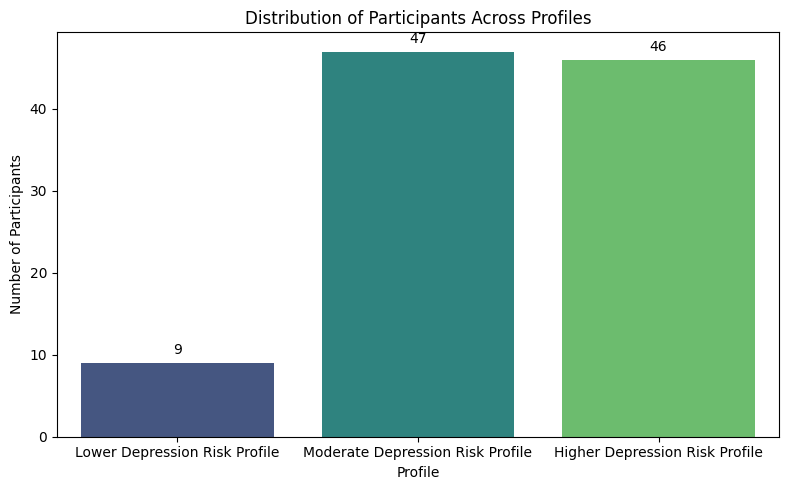

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(8, 5))
ax = sns.barplot(x=order, y=cluster_summary.loc[order, 'Participant Count'], palette='viridis')

plt.title('Distribution of Participants Across Profiles')
plt.xlabel('Profile')
plt.ylabel('Number of Participants')

for p in ax.patches:
    ax.annotate(format(p.get_height(), '.0f'),
                (p.get_x() + p.get_width() / 2., p.get_height()),
                ha='center', va='center', xytext=(0, 9), textcoords='offset points')

plt.tight_layout()
plt.show()

Feature distribution plots (now using signal-bearing features)

/tmp/ipykernel_2274/629574409.py:9: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='cluster_label', y=feature, data=df_clusters, ax=axes[i],
/tmp/ipykernel_2274/629574409.py:9: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='cluster_label', y=feature, data=df_clusters, ax=axes[i],
/tmp/ipykernel_2274/629574409.py:9: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='cluster_label', y=feature, data=df_clusters, ax=axes[i],
/tmp/ipykernel_2274/629574409.py:9: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be 

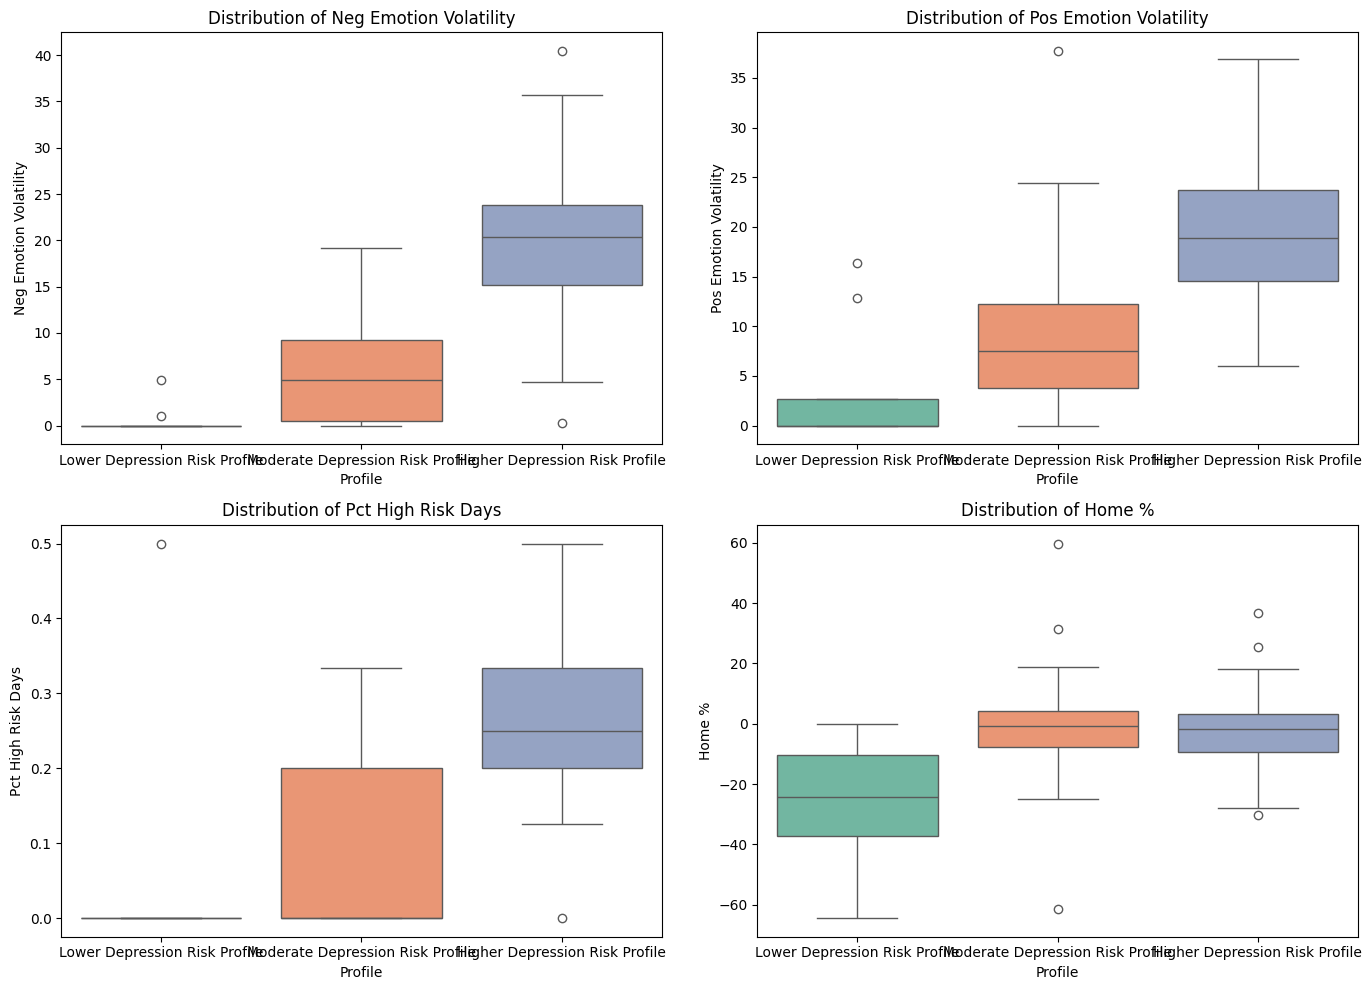

In [ ]:
plot_features = ['neg_emotion_deviation_std', 'pos_emotion_deviation_std',
                  'pct_high_risk_days', 'home_percent_deviation']
available_plot_features = [f for f in plot_features if f in df_clusters.columns]

fig, axes = plt.subplots(2, 2, figsize=(14, 10))
axes = axes.flatten()

for i, feature in enumerate(available_plot_features):
    sns.boxplot(x='cluster_label', y=feature, data=df_clusters, ax=axes[i],
                palette='Set2', order=order)
    title_str = (feature.replace('_deviation_std', ' Volatility')
                         .replace('_deviation', '')
                         .replace('_', ' ').title()
                         .replace('Percent', '%'))
    axes[i].set_title(f'Distribution of {title_str}')
    axes[i].set_xlabel('Profile')
    axes[i].set_ylabel(title_str)

plt.tight_layout()
plt.show()

Risk mapping (unchanged logic, works for K=2 or K=3)

In [ ]:
print("Risk Mapping:")
risk_mapping = df_clusters[['cluster', 'cluster_label']].drop_duplicates().set_index('cluster')['cluster_label'].to_dict()
for cluster, label in sorted(risk_mapping.items()):
    print(f"Cluster {cluster} -> {label}")

Risk Mapping:
Cluster 0 -> Higher Depression Risk Profile
Cluster 1 -> Moderate Depression Risk Profile
Cluster 2 -> Lower Depression Risk Profile


Validation table

In [ ]:
validation_cols = ['neg_emotion_deviation_std', 'pos_emotion_deviation_std',
                    'pct_high_risk_days', 'home_percent_deviation',
                    'entropy_deviation', 'risk_score_mean']
available_val_cols = [c for c in validation_cols if c in df_clusters.columns]

validation_table = df_clusters.groupby(['cluster', 'cluster_label'])[available_val_cols].mean().reset_index()
validation_table['count'] = df_clusters.groupby(['cluster', 'cluster_label']).size().values

col_order = ['cluster', 'cluster_label', 'count'] + available_val_cols
validation_table = validation_table[col_order]

rename_dict = {
    'cluster': 'Cluster',
    'cluster_label': 'Profile',
    'count': 'Participant Count',
    'neg_emotion_deviation_std': 'Neg Emotion Volatility',
    'pos_emotion_deviation_std': 'Pos Emotion Volatility',
    'pct_high_risk_days': '% High-Risk Days',
    'home_percent_deviation': 'Avg Home % Dev',
    'entropy_deviation': 'Avg Entropy Dev',
    'risk_score_mean': 'Avg Risk Score (sanity check, ~0 expected)',
}
validation_table_display = validation_table.rename(columns=rename_dict)
display(validation_table_display)

,Cluster,Profile,Participant Count,Neg Emotion Volatility,Pos Emotion Volatility,% High-Risk Days,Avg Home % Dev,Avg Entropy Dev,"Avg Risk Score (sanity check, ~0 expected)"
0,0,Higher Depression Risk Profile,46,20.547543,19.650635,0.280868,-1.752922,0.069768,-3.288087e-17
1,1,Moderate Depression Risk Profile,47,5.869787,8.837193,0.078080,-0.561186,0.043944,-9.365135e-17
2,2,Lower Depression Risk Profile,9,0.655442,3.831402,0.055556,-27.471699,0.350359,1.948030e-16


Markdown interpretation

In [ ]:
from IPython.display import display, Markdown

def generate_cluster_interpretation(val_table):
    md_text = "### Cluster Interpretation\n\n"

    risk_order = {
        'Lower Depression Risk Profile': 1,
        'Moderate Depression Risk Profile': 2,
        'Higher Depression Risk Profile': 3,
    }
    sorted_table = val_table.copy()
    sorted_table['sort_key'] = sorted_table['Profile'].map(risk_order).fillna(99)
    sorted_table = sorted_table.sort_values('sort_key')

    for _, row in sorted_table.iterrows():
        profile = row['Profile']
        md_text += f"**{profile}**\n\n"

        neg_vol = row.get('Neg Emotion Volatility', 0)
        pos_vol = row.get('Pos Emotion Volatility', 0)
        pct_risk = row.get('% High-Risk Days', 0)
        home = row.get('Avg Home % Dev', 0)

        md_text += f"- Negative-emotion volatility: {neg_vol:.3f}\n"
        md_text += f"- Positive-emotion volatility: {pos_vol:.3f}\n"
        md_text += f"- Share of days flagged high-risk: {pct_risk*100:.1f}%\n"
        home_str = "Higher" if home > 0 else "Lower"
        md_text += f"- {home_str} home time than personal baseline\n\n"

        if profile == 'Lower Depression Risk Profile':
            md_text += "This group shows more stable affect day-to-day and a smaller share of elevated-risk days.\n\n"
        elif profile == 'Moderate Depression Risk Profile':
            md_text += "This group sits between the two extremes on affect volatility and share of high-risk days.\n\n"
        elif profile == 'Higher Depression Risk Profile':
            md_text += "This group shows more volatile affect and/or a higher share of elevated-risk days, consistent with higher depression risk.\n\n"

        md_text += "---\n\n"

    return md_text

interpretation_md = generate_cluster_interpretation(validation_table_display)
display(Markdown(interpretation_md))

### Cluster Interpretation

**Lower Depression Risk Profile**

- Negative-emotion volatility: 0.655
- Positive-emotion volatility: 3.831
- Share of days flagged high-risk: 5.6%
- Lower home time than personal baseline

This group shows more stable affect day-to-day and a smaller share of elevated-risk days.

---

**Moderate Depression Risk Profile**

- Negative-emotion volatility: 5.870
- Positive-emotion volatility: 8.837
- Share of days flagged high-risk: 7.8%
- Lower home time than personal baseline

This group sits between the two extremes on affect volatility and share of high-risk days.

---

**Higher Depression Risk Profile**

- Negative-emotion volatility: 20.548
- Positive-emotion volatility: 19.651
- Share of days flagged high-risk: 28.1%
- Lower home time than personal baseline

This group shows more volatile affect and/or a higher share of elevated-risk days, consistent with higher depression risk.

---

